# Laboratory 2 (Part I)
### Open file, header and bias analysis

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.time import Time
import pickle

## Header and example fits file
Open example fits file and show header

In [2]:
bias00_fits = fits.open('group09_HAT-P-12_20200422/bias/AF608323.fits')
print(bias00_fits)
bias00_fits[0].header

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                   16 / number of bits per data pixel                  
NAXIS   =                    2 / number of data axes                            
NAXIS1  =                  521 / length of data axis 1                          
NAXIS2  =                  250 / length of data axis 2                          
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
BZERO   =                32768 / offset data range to that of unsigned short    
BSCALE  =                    1 / default scaling factor                         
DATE    = '2020-04-23T01:56:26' / file creation date (YYYY-MM-DDThh:mm:ss UT)   
FILENAME= 'AF608323.fits'      / Original file name                             
TIMESYS = 'UTC     '        

Different entries of the header

In [3]:
bias00_fits[0].header['RDNOISE']
bias00_fits[0].header.comments['RDNOISE']

bias00_gain = bias00_fits[0].header['GAIN']
bias00_ron = bias00_fits[0].header['RDNOISE']

bias00_gain_comments = bias00_fits[0].header.comments['GAIN']
bias00_ron_comments = bias00_fits[0].header.comments['RDNOISE']

print('CCD gain = {0:4.2f} {1:.8s}'.format(bias00_gain, bias00_gain_comments))

bias00_time = bias00_fits[0].header['JD']
print('Julian date : {0:12.6f}'.format(bias00_time))

CCD gain = 1.91 [e/ADU] 
Julian date : 2458962.580851


In [4]:
t = Time(bias00_time, format='jd', scale='utc')
print(t.iso)
print(bias00_fits[0].header['DATE'])

2020-04-23 01:56:25.526
2020-04-23T01:56:26


Check size of bias image and plot it

In [5]:
bias00_naxis1 = bias00_fits[0].header['NAXIS1']
bias00_naxis2 = bias00_fits[0].header['NAXIS2']
print(bias00_naxis1, bias00_naxis2)

521 250


(250, 521)


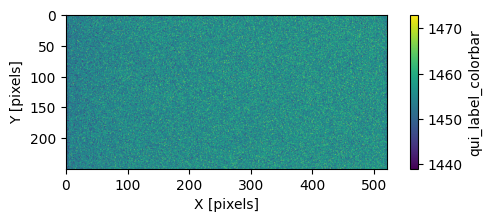

In [6]:
bias00_data = bias00_fits[0].data
print(np.shape(bias00_data))

plt.figure(figsize=(6,2))
plt.imshow(bias00_data)
cbar = plt.colorbar()
cbar.set_label('qui_label_colorbar')
plt.xlabel('X [pixels]')
plt.ylabel('Y [pixels]')
plt.show()

## Bias

Now generalize to all bias files

In [7]:
bias_list = np.genfromtxt('group09_HAT-P-12_20200422/bias/bias.list', dtype=str)
print(bias_list)

['AF608323.fits' 'AF608324.fits' 'AF608325.fits' 'AF608326.fits'
 'AF608327.fits' 'AF608328.fits' 'AF608329.fits' 'AF608330.fits'
 'AF608331.fits' 'AF608332.fits' 'AF608333.fits' 'AF608334.fits'
 'AF608335.fits' 'AF608336.fits' 'AF608337.fits' 'AF608338.fits'
 'AF608339.fits' 'AF608340.fits' 'AF608341.fits' 'AF608342.fits'
 'AF608343.fits' 'AF608344.fits' 'AF608345.fits' 'AF608346.fits'
 'AF608347.fits' 'AF608348.fits' 'AF608349.fits' 'AF608350.fits'
 'AF608351.fits' 'AF608352.fits']


Analysis for the first entry of the bias list

In [8]:
bias00_fits = fits.open('group09_HAT-P-12_20200422/bias/' + bias_list[0])
print(bias00_fits)

gain = bias00_fits[0].header['GAIN']
readoutnoise = bias00_fits[0].header['RDNOISE']
print(gain)  # adu to electrons
print(readoutnoise)  # in electrons

bias00_fits[0].data * gain  # work in electrons for Poisson statistics

1.91
7.1


array([[2790.51, 2773.32, 2777.14, ..., 2769.5 , 2786.69, 2765.68],
       [2775.23, 2782.87, 2773.32, ..., 2786.69, 2779.05, 2782.87],
       [2775.23, 2773.32, 2780.96, ..., 2765.68, 2786.69, 2790.51],
       ...,
       [2786.69, 2750.4 , 2779.05, ..., 2786.69, 2784.78, 2779.05],
       [2767.59, 2767.59, 2775.23, ..., 2779.05, 2782.87, 2777.14],
       [2779.05, 2777.14, 2767.59, ..., 2777.14, 2784.78, 2784.78]])

how to reduce error from bias? take average of many bias frames. 
The error will be reduced by a factor of $\sqrt{N}$, where N is the number of bias frames averaged.

Create an empty array to hold all the bias frames and fill the first slice with the first bias frame

In [9]:
n_images = len(bias_list)
print(n_images)

bias_dim00, bias_dim01 = np.shape(bias00_fits[0].data)
print(bias_dim00, bias_dim01) 

stack = np.empty((n_images, bias_dim00, bias_dim01))
print(stack.shape)

stack[0,:,:] = bias00_fits[0].data * gain 
# print(stack)

30
250 521
(30, 250, 521)


Fill the stack with all the bias frames (generalize what we did before)

In [10]:
for i_bias, bias_name in enumerate(bias_list):
    bias_temp = fits.open('group09_HAT-P-12_20200422/bias/' + bias_name)
    stack[i_bias,:,:] = bias_temp[0].data * gain
    bias_temp.close()  # close the fits file to free up memory

Take the median of the stack along the first axis (the bias frames). Median value of each pixel from every image.

Noise of median bias is reduced wrt original, 30 bias is good compromise between noise reduction and time spent taking bias frames.

In [11]:
median_bias = np.median(stack, axis=0)
print(np.shape(median_bias))

(250, 521)


Plot the bias (in electrons) of the first image and the median value

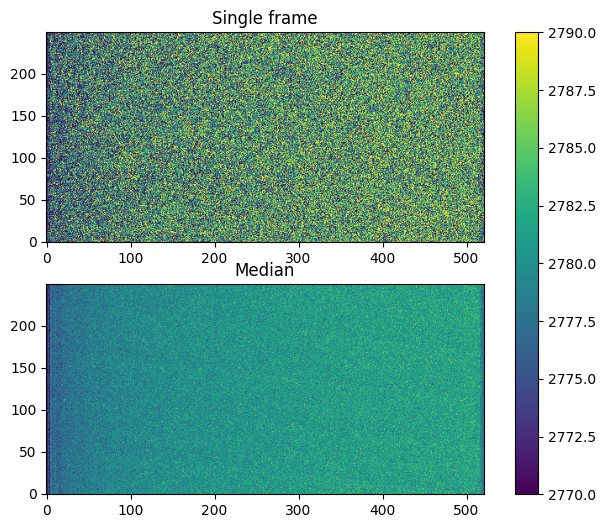

In [12]:
fig, ax = plt.subplots((2), figsize=(8,6))
im = ax[0].imshow(bias00_fits[0].data * gain, vmin=2770, vmax=2790, origin='lower')
ax[1].imshow(median_bias, vmin=2770, vmax=2790, origin='lower')
ax[0].set_title('Single frame')
ax[1].set_title('Median')
fig.colorbar(im, ax=ax)

plt.show()

Brief statistical analysis of the bias frames. Compute the median along each column (axis = 1) and row (axis = 0)

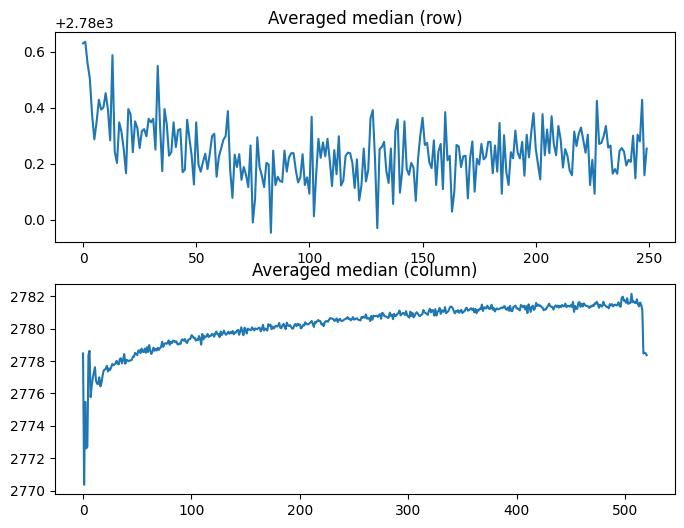

In [ ]:
median_row = np.average(median_bias, axis=1)
median_column = np.average(median_bias, axis=0)

fig, ax = plt.subplots((2), figsize=(8,6))
ax[0].plot(median_row)
ax[1].plot(median_column)
ax[0].set_title('Averaged median (row)')
ax[1].set_title('Averaged median (column)')
plt.show()

Compute standard deviation along each column and row, in a range

Here standard deviation along the rows (?), if axis 1 std along the columns

In [15]:
median_bias_std = np.std(median_bias[:,100:400])
print(median_bias_std)  # in electrons
print(readoutnoise / np.sqrt(n_images))  # in electrons

1.8827230131014174
1.296276719428893


If std of bias is too high you can use the one of pixels (of the stack itself).

Along rows (axis=0) or columns (axis=1).

In [21]:
std_pixels = np.std(stack, axis=0)
print(np.shape(std_pixels))

median_pixel_std = std_pixels / np.sqrt(n_images)
print(median_pixel_std)

(250, 521)
[[1.51597094 1.49406555 1.22360421 ... 1.41142936 1.19500146 1.18540882]
 [1.30813957 1.52361663 1.35875267 ... 1.4238672  1.2486893  1.26593713]
 [1.4886296  1.21267871 1.36549787 ... 1.65455772 1.40855456 1.06971368]
 ...
 [1.02402445 1.51864241 1.44267412 ... 1.30270567 1.44828256 1.49080636]
 [1.17602519 1.37186525 1.42077983 ... 1.26080363 1.4097531  0.97557611]
 [1.25710098 1.02633089 1.48080327 ... 1.17631238 1.25839009 1.41606461]]


Print the std of the pixels

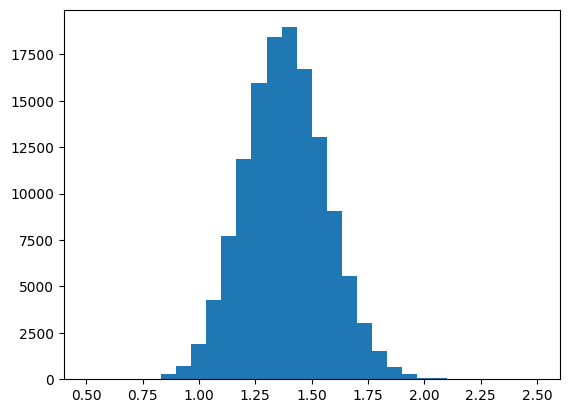

In [22]:
plt.figure()
plt.hist(median_pixel_std.flatten(), bins = 30, range=(0.5, 2.5))
plt.show()

Save the median bias and std to a file for later use, in binary format

In [24]:
pickle.dump(median_bias, open('median_bias.p','wb'))
pickle.dump(median_pixel_std, open('median_bias_errors.p','wb'))